# Cell electrophysiology: currents, gates and model identity

How can an inward current trigger a large voltage excursion, and what does a trustworthy cell simulation need to establish?

Fall 2024.


# Neuronal membrane audit
This is a new neuronal HH teaching implementation, not a cardiac cell. Use mV, ms and µA/cm². Predict the immediate voltage-slope change after a positive inward current. Then predict whether an exact frozen gate starting in [0,1] can leave that interval.

In [1]:
import numpy as np
from membrane import rates, gate_step, rest, ionic_current, simulate
from demo import run
from IPython.display import SVG, display
state = rest()
print("[V,m,h,n] at rest:", state)
print("Net outward current (µA/cm²):", ionic_current(state[0],state[1:]))

[V,m,h,n] at rest: [-6.98976729e+01  5.35746092e-02  5.92537659e-01  3.19246167e-01]
Net outward current (µA/cm²): 8.43769498715119e-15


## Implement a frozen gate
Replace the two `None` expressions using s_inf = alpha/(alpha+beta) and exponential relaxation. Preserve the zero-rate branch. The next cell executes safely before completion and checks a guided example when completed. Explain why the result is bounded.

In [2]:
def my_frozen_gate(s, alpha, beta, dt):
    total = alpha + beta
    if total == 0:
        return s
    equilibrium = None  # TODO: equilibrium gate fraction
    if equilibrium is None:
        return None
    updated = None  # TODO: exact exponential relaxation from s
    return updated

trial = my_frozen_gate(0.9, 0.2, 0.3, 1.0)
if trial is None:
    print("Complete both expressions, then rerun this cell.")
else:
    np.testing.assert_allclose(trial, 0.7032653298563167, rtol=0, atol=1e-12)
    print("Guided frozen-rate check passed:", trial)

Complete both expressions, then rerun this cell.


In [3]:
print("alpha_m at −45 mV:", rates(-45.)[0][0])
print("alpha_n at −60 mV:", rates(-60.)[0][2])
quiet = simulate(amplitude=0, end=5)
print("Maximum rest drift:", np.max(abs(quiet["state"]-state)))
for amplitude in [2., 5., 10.]:
    response = simulate(amplitude=amplitude)
    print(amplitude, "µA/cm²; peak", response["peak_mV"], "mV; gate range", response["gate_min"], response["gate_max"])

alpha_m at −45 mV: 1.0
alpha_n at −60 mV: 0.1
Maximum rest drift: 7.105427357601002e-13


2.0 µA/cm²; peak -68.26225810535843 mV; gate range 0.050884890256194214 0.5933366958539477


5.0 µA/cm²; peak -65.69027513727988 mV; gate range 0.04573955457007621 0.5936651834611235
10.0 µA/cm²; peak 33.96217211622026 mV; gate range 0.013562699724249602 0.9936018761583811


## Run and interpret
The figure uses equal pulse durations and the same initial state. State an observable that distinguishes the responses. The smooth-state error test is different from the pulse experiment: identify its reference, tested time and expected asymptotic order.

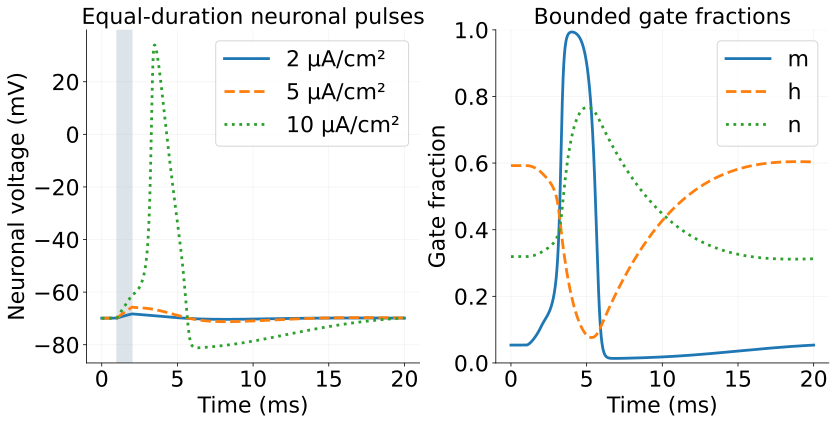

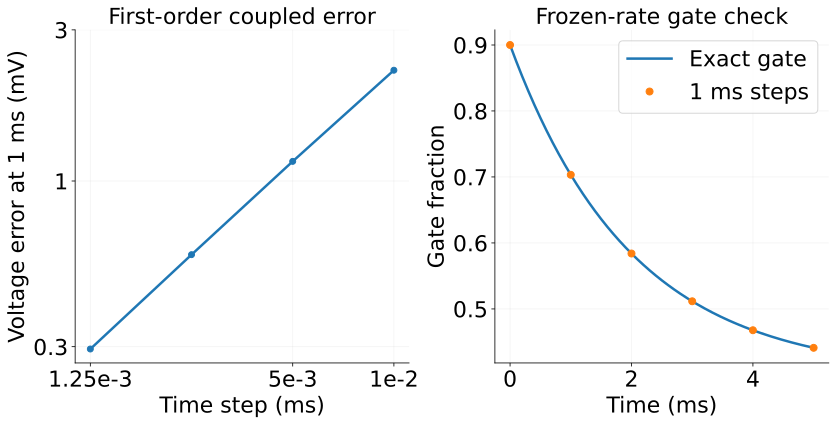

Observed smooth-state orders: [0.9555061590075283, 0.978175113308603, 0.9892017402076492]


In [4]:
results = run()
display(SVG(filename="neuronal-cell.svg"))
display(SVG(filename="gate-and-time-checks.svg"))
print("Observed smooth-state orders:", results["observed_orders"])

## Modify one control
Predict what happens when the 5 µA/cm² pulse lasts 2 ms. Run the case below, then repeat it with half the step. Report the observed response and its sensitivity; do not call it a universal threshold.

In [5]:
for step in [0.005, 0.0025]:
    changed = simulate(amplitude=5, duration=2, dt=step)
    print("dt",step,"peak",changed["peak_mV"],"charge",changed["charge_uA_ms_cm2"])

dt 0.005 peak 33.26437352199965 charge 9.999999999999936
dt 0.0025 peak 33.264138415023346 charge 9.999999999999893


## Record your interpretation
Write the model identity, sign convention, one verified implementation property, one time-accuracy observation and one biological claim these runs do not establish. Optional: extend to a duration–amplitude grid after the core audit is complete.